<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_070_dbscan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 70/365 — DBSCAN
## What if clusters are irregularly shaped and we also want to detect noise?

Yesterday we explored **Hierarchical Clustering**.

Today we move to:

**DBSCAN — Density-Based Spatial Clustering of Applications with Noise**

Unlike K-Means, DBSCAN does **not** require us to choose the number of clusters in advance.

It looks for dense regions of points and can leave isolated points as noise.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans


## 1. Create nonlinear unlabeled data


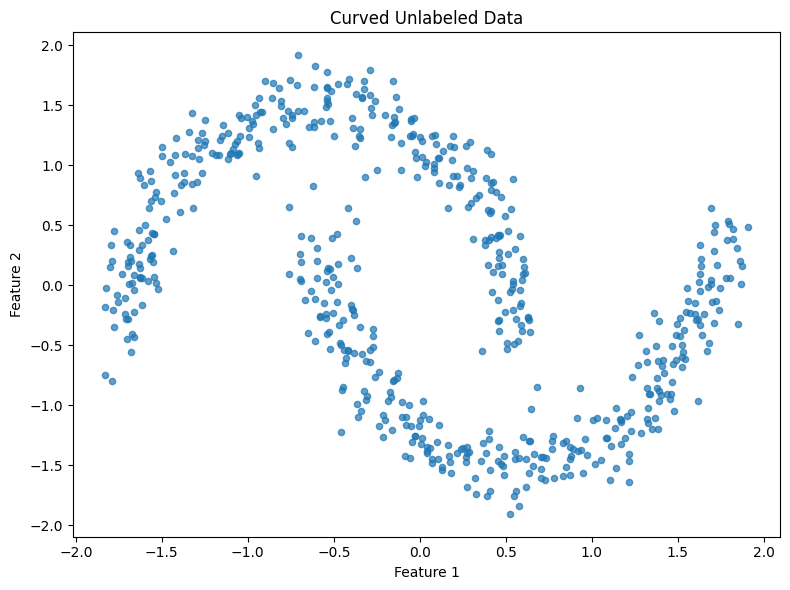

In [2]:
X,_=make_moons(
    n_samples=600,
    noise=0.08,
    random_state=42
)

X=StandardScaler().fit_transform(X)

plt.figure(figsize=(8,6))
plt.scatter(X[:,0],X[:,1],s=20,alpha=0.7)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Curved Unlabeled Data")
plt.tight_layout()
plt.show()


## 2. Compare with K-Means

K-Means prefers compact, roughly spherical clusters.


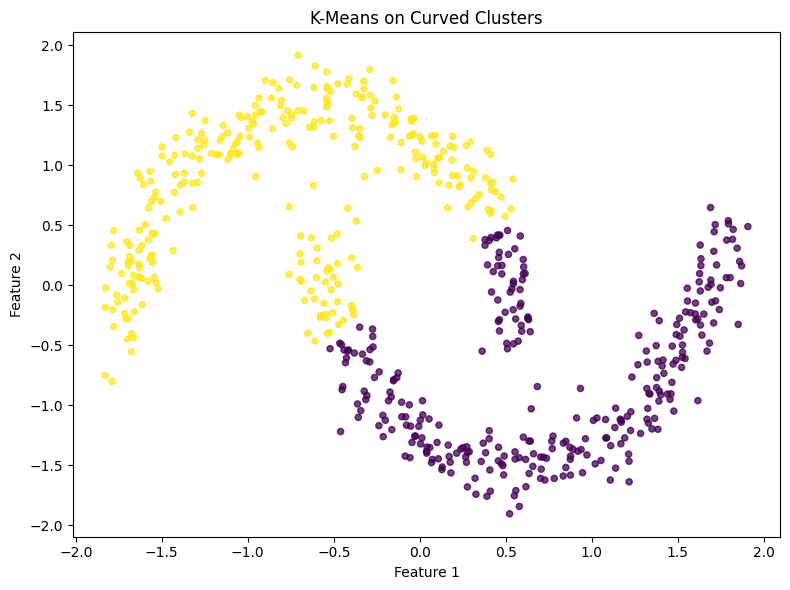

In [3]:
kmeans=KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_labels=kmeans.fit_predict(X)

plt.figure(figsize=(8,6))
plt.scatter(X[:,0],X[:,1],c=kmeans_labels,s=20,alpha=0.75)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means on Curved Clusters")
plt.tight_layout()
plt.show()


## 3. Train DBSCAN

Two important parameters:

### `eps`
Neighborhood radius.

### `min_samples`
Minimum number of nearby observations required for a dense region.

DBSCAN labels noise points as:

`-1`


In [4]:
dbscan=DBSCAN(
    eps=0.3,
    min_samples=5
)

dbscan_labels=dbscan.fit_predict(X)

labels,counts=np.unique(
    dbscan_labels,
    return_counts=True
)

display(pd.DataFrame({
    "Label":labels,
    "Count":counts
}))


,Label,Count
0,0,600


## 4. Visualize DBSCAN


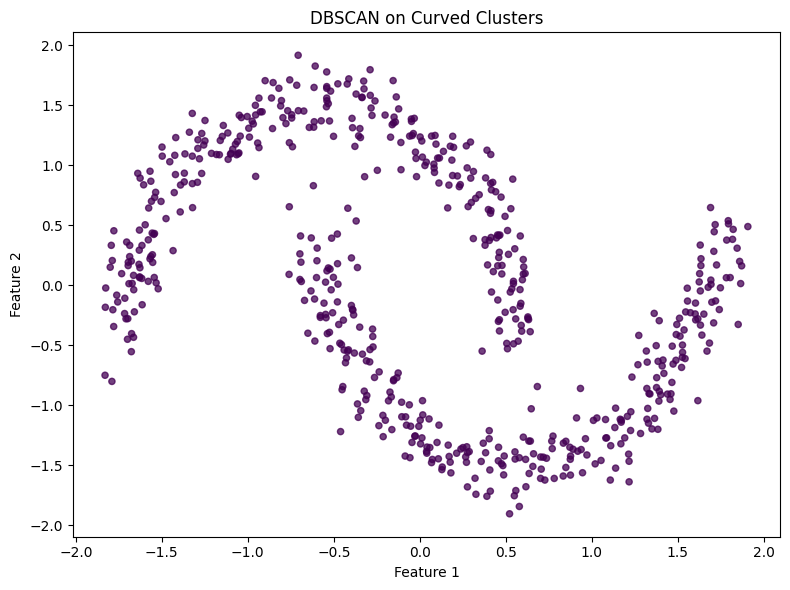

In [5]:
plt.figure(figsize=(8,6))
plt.scatter(
    X[:,0],
    X[:,1],
    c=dbscan_labels,
    s=20,
    alpha=0.75
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("DBSCAN on Curved Clusters")
plt.tight_layout()
plt.show()


## 5. Core, border and noise points

### Core Point
Has enough neighbors within `eps`.

### Border Point
Is close to a core point but does not itself have enough neighbors.

### Noise Point
Does not belong to a sufficiently dense region.


In [6]:
noise_count=np.sum(dbscan_labels==-1)

print("Noise points:",noise_count)
print(
    "Noise percentage:",
    round(noise_count/len(X)*100,2),
    "%"
)


Noise points: 0
Noise percentage: 0.0 %


## 6. K-Means vs DBSCAN

### K-Means
- choose K
- uses centroids
- prefers compact clusters
- assigns every point somewhere

### DBSCAN
- no K required
- uses density
- handles irregular shapes
- can mark points as noise


## 7. Parameter intuition

Small `eps`:
- many points may become noise
- clusters may fragment

Large `eps`:
- separate clusters may merge

Larger `min_samples`:
- requires denser regions to create a cluster


## Enterprise intuition

DBSCAN is useful when we care about dense groups plus unusual isolated observations.

Examples:
- fraud/anomaly exploration
- geospatial clustering
- network-event grouping
- customer behavior segmentation
- telemetry analysis

An isolated point is not automatically fraud or an anomaly, but DBSCAN can help flag unusual observations for further investigation.


## Important limitations

DBSCAN can struggle when:
- clusters have very different densities
- `eps` is difficult to choose
- the data has many dimensions

In high-dimensional spaces, distance itself becomes less informative.


## What does this teach?

- DBSCAN is density-based clustering.
- It does not require K.
- It can discover nonlinear cluster shapes.
- It can identify noise points.
- `eps` controls neighborhood size.
- `min_samples` controls density requirements.

> **K-Means asks: which centroid are you closest to? DBSCAN asks: are you part of a dense neighborhood at all?**


## References

- https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html
- https://scikit-learn.org/stable/modules/clustering.html#dbscan
- https://www.aaai.org/Papers/KDD/1996/KDD96-037.pdf
